## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

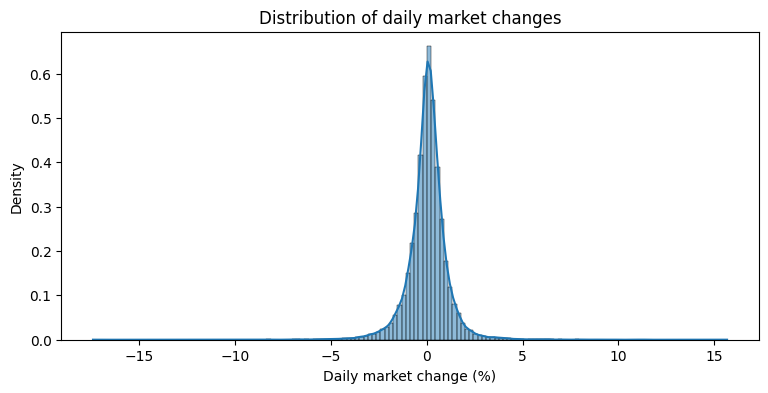

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

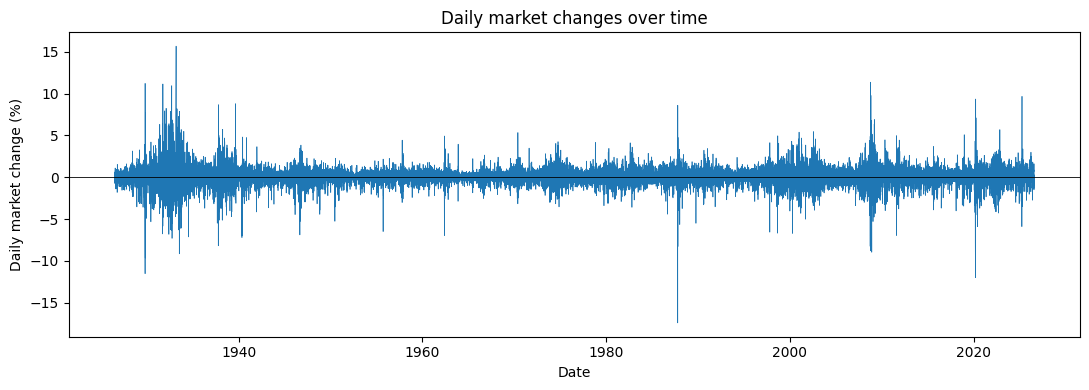

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF.
- Are up transitions more or less common than down transitions?
- Are you more likely to transition to an Up day from a Down or Up day?

In [6]:
# make a categorical column "direction_t"
directional_categories = {"Down / flat", "Up"}
np.where(df["market_return_pct"] > 0, 'Up', 'Down / flat')
df['direction_t'] = pd.Categorical(
    np.where(df["market_return_pct"] > 0, 'Up', 'Down / flat'),
    categories=directional_categories,
    ordered=True
)

In [7]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [8]:
crosstab = pd.crosstab(df["direction_t"], df["direction_tp1"], normalize=True, margins=True)
crosstab

direction_tp1,Up,Down / flat,All
direction_t,,,
Up,0.318996,0.228142,0.547138
Down / flat,0.228142,0.224720,0.452862
All,0.547138,0.452862,1.000000


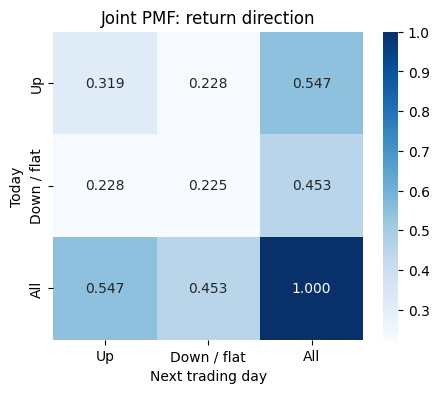

In [9]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(crosstab,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [10]:
conditional_crosstab = pd.crosstab(df["direction_t"], df["direction_tp1"], normalize='index')
conditional_crosstab

direction_tp1,Up,Down / flat
direction_t,,
Up,0.583026,0.416974
Down / flat,0.503779,0.496221


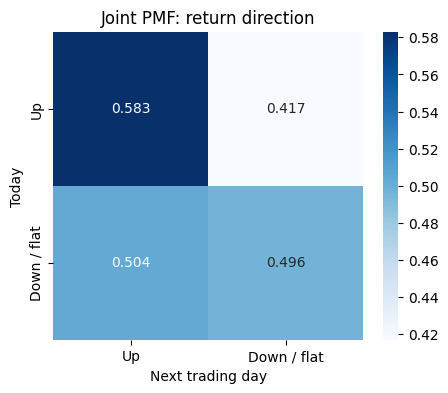

In [11]:
# Plot the conditional PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(conditional_crosstab,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions?
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

**Answer** <br>
- Up transitions are more common than down transitions
- It is more likely to transition from an up-day to another up-day (0.583) than it is to transition from a down/flat day to an up day (0.504).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur?
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this.

In [12]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df["market_return_pct"], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=return_categories)

In [13]:
df["return_bin"]

,return_bin
0,Near zero
1,Small gain
2,Small gain
3,Near zero
4,Small gain
...,...
26291,Small gain
26292,Small gain
26293,Large loss
26294,Large gain


In [14]:
df["return_bin"].value_counts()

,count
return_bin,
Small gain,9785
Small loss,7452
Near zero,3441
Large gain,2859
Large loss,2759


In [15]:
#make y_t and y_tp1 columns for the return bins
df["y_t"] = df["return_bin"]
df["y_tp1"] = df["return_bin"].shift(-1)

In [16]:
y_crosstab = pd.crosstab(df["y_t"], df["y_tp1"], normalize=True, margins=True)
y_crosstab

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

**Answer** <br>
- \# of small gains = 9785, \# of small losses = 7452, \# of near zeroes = 3441, \# of large gains = 2859, \# of large losses = 2759
- Small gains are the most common, while large losses are the least common

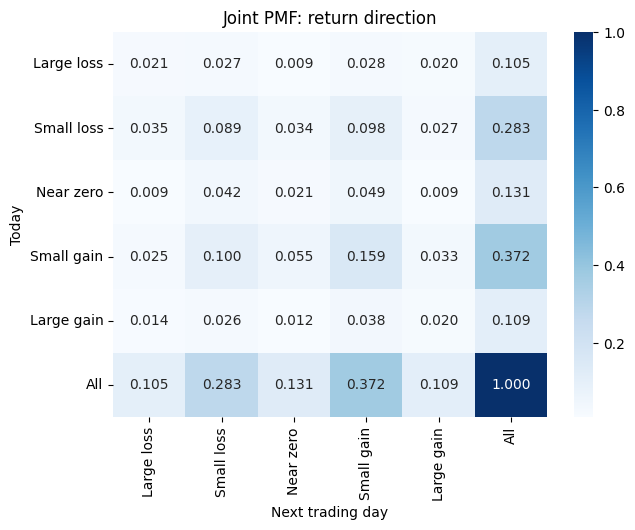

In [17]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(y_crosstab,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur?

</div>

**Answer** <br>
A small gain transition from a small gain is the most likely to occur.

In [18]:
#conditional PMF
y_conditional_crosstab = pd.crosstab(df["y_t"], df["y_tp1"], normalize="index")
y_conditional_crosstab

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


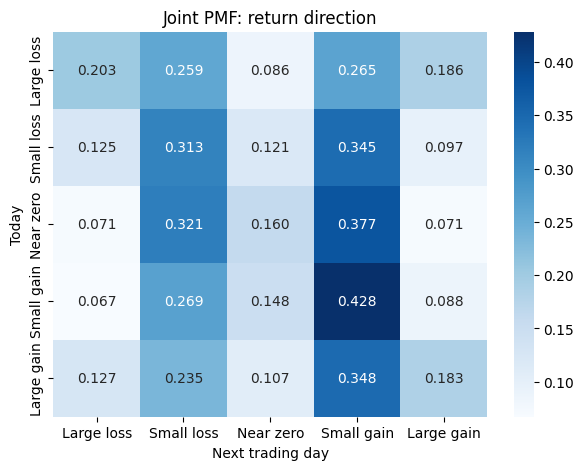

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(y_conditional_crosstab,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely?
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition?
- Is it relatively easy or difficult to predict the next state?
</div>

**Answer** <br>
- For every current state, a transition to a small loss or small gain is the most likely.
- The rows are not particularly close to a uniform mass function; the most likely probabilities exceed 0.2 by around 0.15 or even over 0.2, while the least likely probabilites can be more than 0.1 less than 0.2.
- It is relatively easy to predict the next state, because the rows are not uniform and some states are clearly more likely than others.

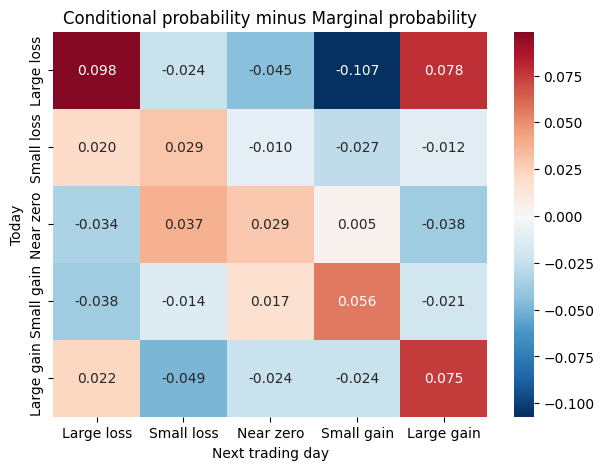

In [20]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df["y_t"], df["y_tp1"], normalize=True).sum(axis=0)

# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(y_conditional_crosstab.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional probability minus Marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

**Answer** <br>
- The transitions that contain positive values and colored red/orange, such as large loss -> large loss and large gain -> large loss, are more likely than independence predicts. The transitions that contain negative values and are more bluish indicate a lower probability than independence predicts, such as small gain -> large loss or small loss -> small gain.
- Knowing today's state changes the forecast for tomorrow. If this was not the case, then the heatmap would contain only zeroes.
- This comparison checks for independence of events by seeing if today's outcome affects the next day's outcome. A uniform PMF checks if all future states are equally likely . Uniformity and independence are different concepts and comparisons.

In [21]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct_tp1"].describe()
# if today there was a large gain, what is the expected market return tomorrow? 0.163092

/tmp/ipykernel_6457/3094766646.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow?
- How do the min and max values for tomorrow vary across states?
- Which states have the highest standard deviation for tomorrow's percent returns?
- Describe any patterns in the volatility you notice.
</div>


**Answer** <br>
- The expected percent returns for a given current state are given by the mean column.
- The large loss and large gain have the highest difference between the min and max, and the min and max for these states are also relatively unbalanced around 0 (-17-11, -12-15). The small loss and small gain have a smaller range between the min and max, and are also much more balanced around 0 (-11.23-11.36, -8.25-8.67). The near-zero state has the smallest range between the min and max.
- Large losses and large gains have the highest standard deviations for tomorrow's returns.
- Large losses and large gains have a significantly higher volatility / standard deviation than the others. Losses both large and small tend to have a higher volatility than gains.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`.
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain.
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.
- How easy is it to predict the market?

In [22]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


<Axes: xlabel='y_tp1', ylabel='y_t'>

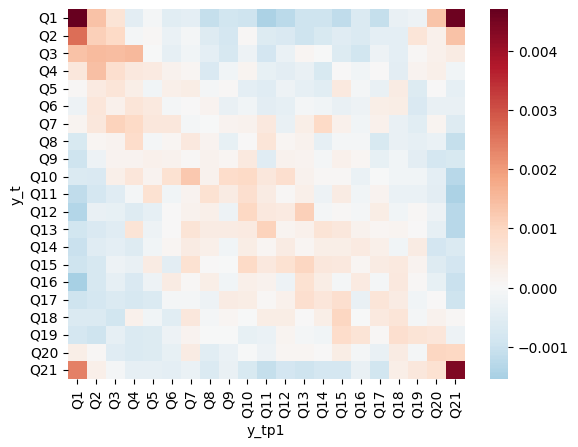

In [34]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df["y_t"], df["y_tp1"], normalize=True, margins=False
)

sns.heatmap(quantile_joint - 1/bins**2, cmap="RdBu_r", center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Answer** <br>
The 4 corners have a very 'high heat' so extreme bins are more likely to transition to other extreme bins.

<Axes: xlabel='y_tp1', ylabel='y_t'>

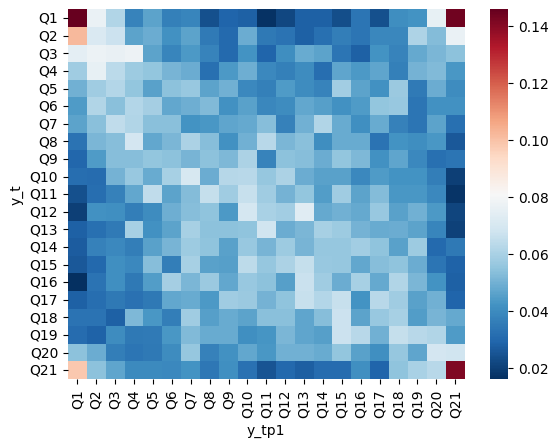

In [33]:
# compute and plot the conditional
quantile_conditional = pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize="index",
    margins=False
)

sns.heatmap(quantile_conditional, cmap="RdBu_r")


<Axes: xlabel='y_tp1', ylabel='y_t'>

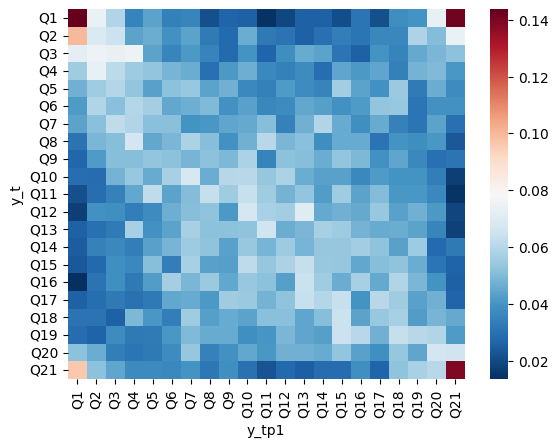

In [32]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF,
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_conditional - 1/bins**2, cmap="RdBu_r")

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Answer** <br>
Similar to the quantile joint PMF, the corners have high heat, suggesting extreme bins are much more likely given that the day prior was an extreme bin.

In [37]:
# compute the next day's min, mean, and max conditional on each bin
df["return_tp1"] = df["market_return_pct"].shift(-1)
next_day_stats = (df.groupby("y_t", observed=False)["return_tp1"].agg(["min", "mean", "max"]))

next_day_stats

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


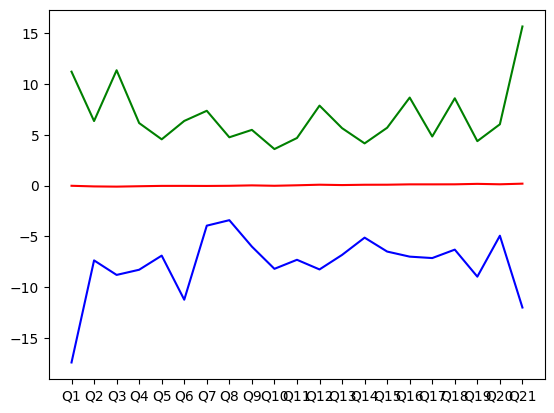

In [38]:
#plot as lines on a graph against the bins
plt.plot(next_day_stats.index, next_day_stats["mean"], color="red")
plt.plot(next_day_stats.index, next_day_stats["min"], color="blue")
plt.plot(next_day_stats.index, next_day_stats["max"], color="green")

plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Answer** <br>
Mins and maxes appear to be mirrored /flipped across the mean, showing that when one goes up, the other goes down. The mean itself is a near perfectly straight line at y=0.

In [39]:
#compute the next day's standard deviation, and plot it as a line graph against the bins.
next_day_std = (df.groupby("y_t", observed=False)["return_tp1"].agg(["std"]))
next_day_std

,std
y_t,
Q1,2.140465
Q2,1.285882
Q3,1.227976
Q4,1.049607
Q5,0.989470
Q6,1.024761
Q7,0.930389
Q8,0.835663
Q9,0.853220


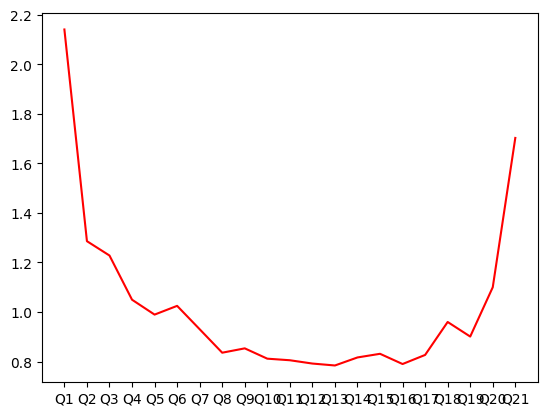

In [40]:
plt.plot(next_day_std.index, next_day_std["std"], color="red")

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Answer** <br>
Standard deviations are highest at extreme bins (Q1, Q21) and lowest in the middle bins (Q8-Q17), making a parabolic curve.

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

**Answer** <br>
It is relatively easy to predict this market, or at least understand the risks associated with decisions. For example, large losses and gains consistently have high volatility. Small losses and small gains are consistently most likely to happen on the next day regardless of the current day's state. These patterns make it easier to navigate the market and make reliable decisions.